# Configuración manual final - CNN

Este notebook contiene la mejor configuración obtenida mediante búsqueda manual
de hiperparámetros y entrenamiento desde cero.

La arquitectura final manual corresponde a la Configuración 10, formada por
cuatro capas convolucionales con Batch Normalization, Data Augmentation,
Adaptive Average Pooling y Dropout.

In [1]:
import os
import copy
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 1. Carga y preparación del dataset

In [2]:
ruta_dataset = "../dataset_cat"

In [5]:
transform_train = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor()
])

transform_eval = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor()
])

In [6]:
dataset_train = ImageFolder(
    root=ruta_dataset,
    transform=transform_train
)

dataset_eval = ImageFolder(
    root=ruta_dataset,
    transform=transform_eval
)

print("Número de imágenes:", len(dataset_eval))
print("Clases:", dataset_eval.classes)
print("Etiquetas:", dataset_eval.class_to_idx)

Número de imágenes: 1613
Clases: ['Abyssinian', 'Bengal', 'Bombay', 'British Shorthair', 'Egyptian Mau', 'Maine Coon', 'Persian', 'Ragdoll', 'Siamese', 'Sphynx']
Etiquetas: {'Abyssinian': 0, 'Bengal': 1, 'Bombay': 2, 'British Shorthair': 3, 'Egyptian Mau': 4, 'Maine Coon': 5, 'Persian': 6, 'Ragdoll': 7, 'Siamese': 8, 'Sphynx': 9}


## 2. División del dataset

El dataset se divide de forma estratificada en:

- 70 % entrenamiento
- 15 % validación
- 15 % test

Se utiliza `random_state=42` para mantener la misma división utilizada
durante los experimentos anteriores.

In [8]:
indices = np.arange(len(dataset_eval))
etiquetas = dataset_eval.targets

indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

print("Entrenamiento:", len(indices_train))
print("Validación:", len(indices_val))
print("Test:", len(indices_test))

Entrenamiento: 1129
Validación: 242
Test: 242


In [9]:
train_dataset = Subset(
    dataset_train,
    indices_train
)

val_dataset = Subset(
    dataset_eval,
    indices_val
)

test_dataset = Subset(
    dataset_eval,
    indices_test
)

## 3. DataLoaders

Se utiliza un tamaño de lote de 32.

El conjunto de entrenamiento se baraja en cada época, mientras que
validación y test mantienen un orden fijo.

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [11]:
imagenes, etiquetas = next(iter(train_loader))

print("Forma imágenes:", imagenes.shape)
print("Forma etiquetas:", etiquetas.shape)

Forma imágenes: torch.Size([32, 3, 160, 160])
Forma etiquetas: torch.Size([32])


## 4. Arquitectura de la CNN

La configuración manual final utiliza cuatro capas convolucionales.

Arquitectura:

- Conv1: 3 → 32 filtros
- Conv2: 32 → 64 filtros
- Conv3: 64 → 128 filtros
- Conv4: 128 → 256 filtros
- Batch Normalization después de cada convolución
- MaxPooling 2x2
- Adaptive Average Pooling 4x4
- Capa completamente conectada de 128 neuronas
- Dropout de 0.5
- Capa de salida de 10 neuronas

In [12]:
class CNN_Config10(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.fc1 = nn.Linear(256 * 4 * 4, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

model = CNN_Config10().to(device)

Dispositivo: cpu


In [15]:
model = CNN_Config10().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

max_epochs = 70
patience = 8
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [17]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    scheduler.step(val_loss)


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/70 - Train Loss: 2.2999 - Val Loss: 2.2809 - Train Accuracy: 15.06% - Val Accuracy: 13.64%
Época 02/70 - Train Loss: 2.0942 - Val Loss: 2.0141 - Train Accuracy: 23.65% - Val Accuracy: 30.99%
Época 03/70 - Train Loss: 2.0197 - Val Loss: 1.9480 - Train Accuracy: 27.72% - Val Accuracy: 30.17%
Época 04/70 - Train Loss: 1.9777 - Val Loss: 1.9136 - Train Accuracy: 29.50% - Val Accuracy: 30.99%
Época 05/70 - Train Loss: 1.9189 - Val Loss: 1.8399 - Train Accuracy: 31.18% - Val Accuracy: 35.54%
Época 06/70 - Train Loss: 1.8312 - Val Loss: 1.9504 - Train Accuracy: 33.66% - Val Accuracy: 30.17%
Época 07/70 - Train Loss: 1.8051 - Val Loss: 1.8308 - Train Accuracy: 32.95% - Val Accuracy: 35.54%
Época 08/70 - Train Loss: 1.7801 - Val Loss: 1.8503 - Train Accuracy: 35.08% - Val Accuracy: 35.95%
Época 09/70 - Train Loss: 1.7596 - Val Loss: 1.5683 - Train Accuracy: 35.78% - Val Accuracy: 41.74%
Época 10/70 - Train Loss: 1.7139 - Val Loss: 1.5594 - Train Accuracy: 37.11% - Val Accuracy: 45.04%


<All keys matched successfully>

In [18]:
results_dir = "../results"
os.makedirs(results_dir, exist_ok=True)

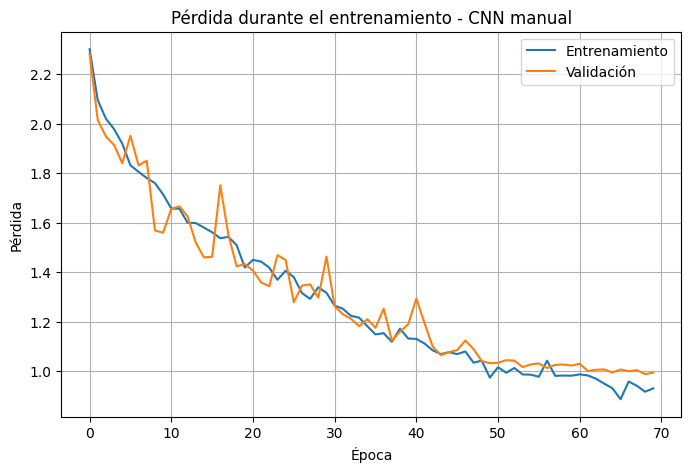

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Entrenamiento")
plt.plot(val_losses, label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento - CNN manual")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(results_dir, "manual_loss.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

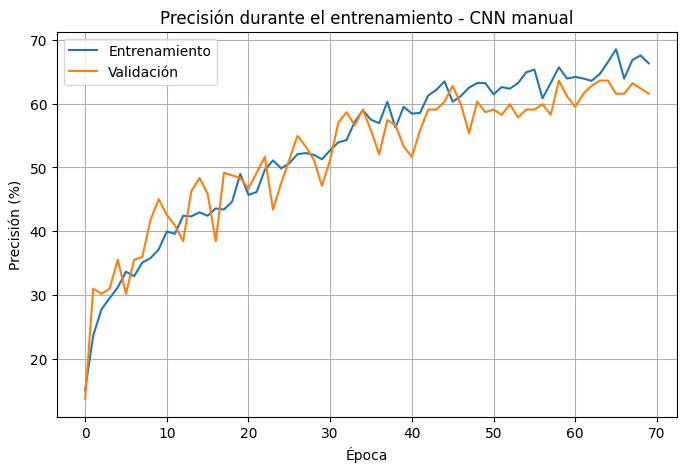

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Entrenamiento")
plt.plot(val_accuracies, label="Validación")

plt.xlabel("Época")
plt.ylabel("Precisión (%)")
plt.title("Precisión durante el entrenamiento - CNN manual")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(results_dir, "manual_accuracy.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [21]:
y_true_val = []
y_pred_val = []

model.eval()

with torch.no_grad():

    for imagenes, etiquetas in val_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = model(imagenes)
        predicciones = salidas.argmax(dim=1)

        y_true_val.extend(etiquetas.cpu().numpy())
        y_pred_val.extend(predicciones.cpu().numpy())

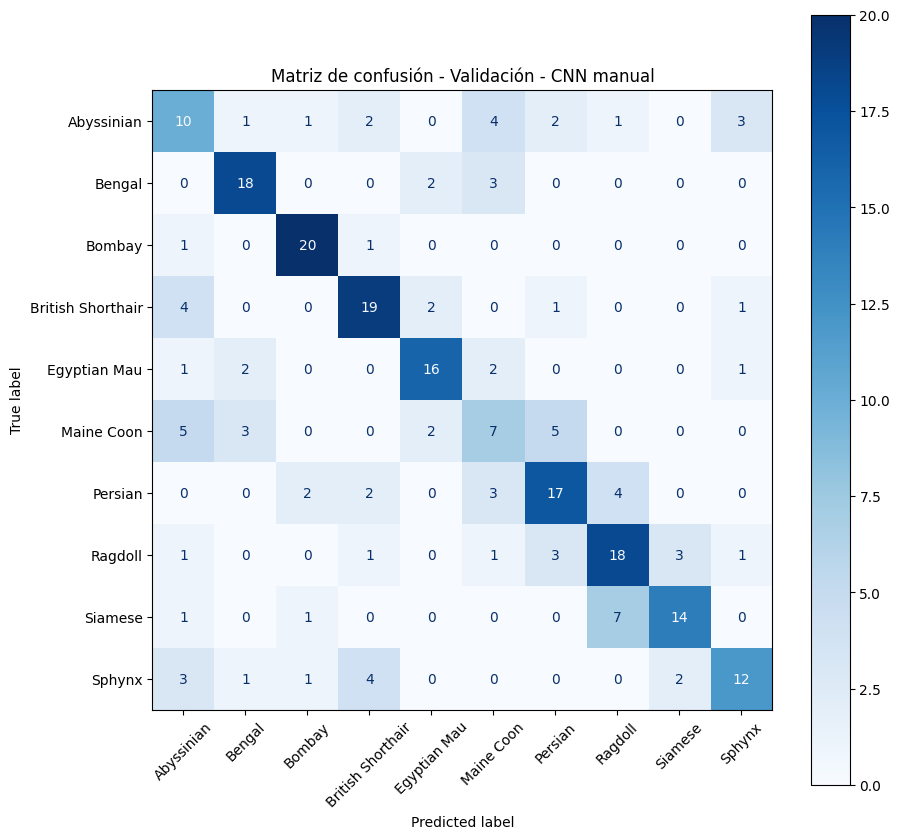

In [22]:
matriz_val = confusion_matrix(
    y_true_val,
    y_pred_val
)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_val,
    display_labels=dataset_eval.classes
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Matriz de confusión - Validación - CNN manual")

plt.savefig(
    os.path.join(results_dir, "manual_confusion_validation.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
model.eval()

test_running_loss = 0.0
test_correct = 0
test_total = 0

y_true_test = []
y_pred_test = []

with torch.no_grad():

    for imagenes, etiquetas in test_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        test_running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        test_correct += (predicciones == etiquetas).sum().item()
        test_total += etiquetas.size(0)

        y_true_test.extend(etiquetas.cpu().numpy())
        y_pred_test.extend(predicciones.cpu().numpy())

test_loss = test_running_loss / test_total
test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.8099
Test Accuracy: 73.14%


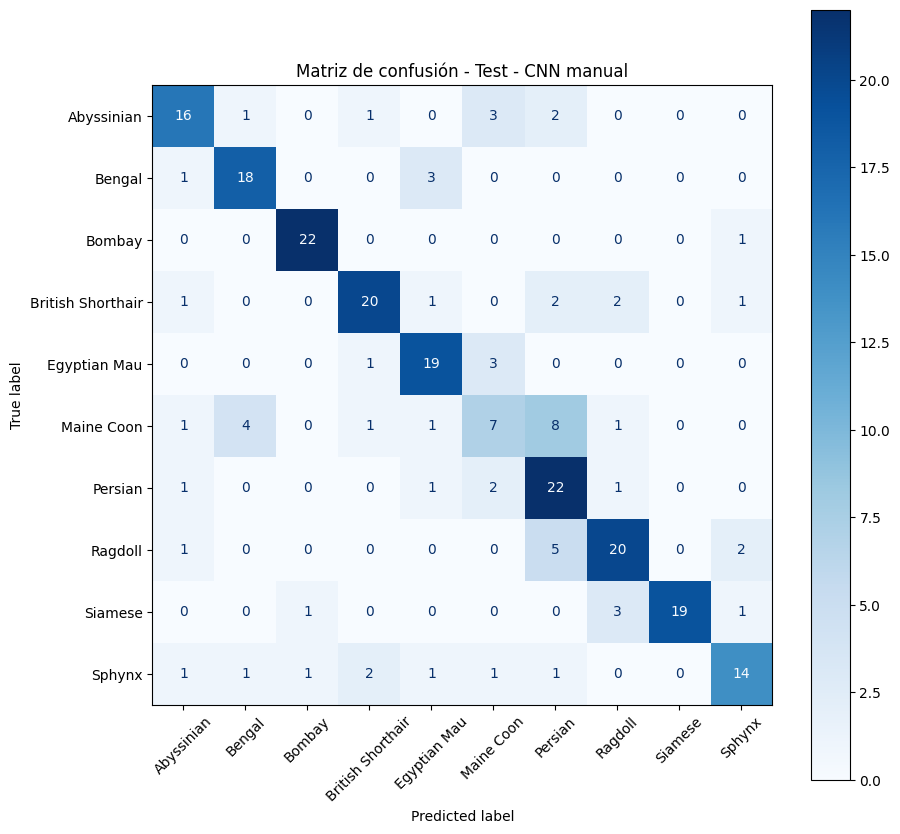

In [24]:
matriz_test = confusion_matrix(
    y_true_test,
    y_pred_test
)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=dataset_eval.classes
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Matriz de confusión - Test - CNN manual")

plt.savefig(
    os.path.join(results_dir, "manual_confusion_test.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()